# W3e — winnica wobec sąsiadów (eksperyment, D-092)

**Pytanie.** W suchym roku prawie wszystkie winnice są naraz „poniżej swojej normy” (W3b T1: w 2022 r. 76% scen).
To mówi o pogodzie, a nie o konkretnej winnicy. Czy porównanie winnicy z sąsiadami **tego samego dnia** usuwa
wspólną pogodę i zostawia to, co dotyczy samej winnicy?

**Metoda** (protokół `docs/evidence/W3e_protokol_sasiedzi.md`, zarejestrowany przed liczeniem):
1. d = z_woda winnicy − mediana z_woda pozostałych winnic tego dnia (≥ 6 sąsiadów);
2. z_rel = d / skala, skala = 1,4826·MAD z d **tylko z lat wcześniejszych** (bez przyszłości);
3. cztery testy z kryteriami ustalonymi z góry: H1 kalibracja, H2 niezależność od roku, H3 niezależność od gleby,
   H4 czy przesadzenia z rejestru RPG wyróżniają się w z_rel.

**Jak czytać.** Każda sekcja kończy się wierszem *spełnione / niespełnione*. Decyzja w §7. Wynik negatywny też jest
wynikiem. To eksperyment eksploracyjny: potwierdzenie dopiero na sezonie 2027.

## 0. Dane i protokół

In [1]:
import os, sys, json
CODE_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', '..')) if os.path.basename(os.getcwd()) == 'experiments' \
    else os.path.abspath('.')
sys.path.insert(0, CODE_DIR)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from agriscreen import local, parcel
from agriscreen.config import make_config, era5_csv

settings = local.load_settings()
cfg = make_config(CODE_DIR, data_dir=settings['data_dir'])
OUT = cfg['OUTPUT_DIR']
PROTO = os.path.join(CODE_DIR, 'docs', 'evidence', 'W3e_protokol_sasiedzi.md')
sha = parcel.protocol_sha(PROTO)
assert sha['status'] == 'REGISTERED' and sha['sha256'] == sha['registered'], f'protokół zmieniony po rejestracji: {sha}'
print(f"Protokół W3e: {sha['status']}, SHA-256 {sha['sha256'][:16]}… (zgodny z zarejestrowanym)")

FREEZE = json.load(open(os.path.join(OUT, 'w3b_freeze.json'), encoding='utf-8'))['freeze']
P_BELOW = 0.159                        # udział N(0,1) ≤ −1
pa = pd.read_csv(os.path.join(OUT, 'parcel_anomalies.csv'), parse_dates=['time'])
sites = parcel.qc_sites(pa)
era5 = pd.read_csv(era5_csv(cfg), parse_dates=['time'])
soil = parcel.soil_pct(era5, cfg)
soil.index = pd.DatetimeIndex(soil.index).normalize()
soil = soil[~soil.index.duplicated(keep='last')]
rpg = pd.read_csv(os.path.join(CODE_DIR, 'data', 'rpg_winnice.csv'))
print(f'Zamrożenie W3b: {FREEZE}; winnice z QC: {len(sites)}; RPG: {len(rpg)} wierszy')

Protokół W3e: REGISTERED, SHA-256 ff20babadf13aa75… (zgodny z zarejestrowanym)


Zamrożenie W3b: 2026-10-18; winnice z QC: 13; RPG: 150 wierszy


## 1–2. Różnica wobec sąsiadów (d) i z_rel
Dla każdej winnicy i dnia: d = z_woda − mediana pozostałych winnic z QC (≥ 6 z wartością). Skala dla roku y:
1,4826·MAD z d ze scen VI–IX lat < y (≥ 30 wartości z ≥ 2 lat).

In [2]:
w = pa[(pa['index'] == 'water') & pa['site_id'].isin(sites)].dropna(subset=['z']).copy()
w['day'] = w['time'].dt.normalize()
piv = w.pivot_table(index='day', columns='site_id', values='z', aggfunc='last')
d_parts = []
for s in piv.columns:
    others = piv.drop(columns=s)
    med = others.median(axis=1).where(others.notna().sum(axis=1) >= cfg['PARCEL_MIN_AREA'])
    d_parts.append(pd.DataFrame({'site_id': s, 'day': piv.index, 'z': piv[s].to_numpy(),
                                 'nbr_med': med.to_numpy(), 'd': (piv[s] - med).to_numpy()}))
D = pd.concat(d_parts).dropna(subset=['z', 'd'])
D['year'] = D['day'].dt.year
D['summer'] = D['day'].dt.month.between(*cfg['PARCEL_TEST_MONTHS'])

def scale(g):
    """Skala z lat wcześniejszych dla każdego roku winnicy (§2)."""
    out = {}
    for y in sorted(g['year'].unique()):
        prev = g[(g['year'] < y) & g['summer']]['d']
        n_years = g[(g['year'] < y) & g['summer']]['year'].nunique()
        if len(prev) >= 30 and n_years >= 2:
            out[y] = 1.4826 * float(np.median(np.abs(prev - np.median(prev))))
    return pd.Series(out, dtype=float)

S = {s: scale(g) for s, g in D.groupby('site_id')}
D['s'] = [S[s].get(y, np.nan) for s, y in zip(D['site_id'], D['year'])]
D['z_rel'] = D['d'] / D['s']

T = D[D['summer'] & D['year'].between(2018, 2026) & (D['day'] <= pd.Timestamp(FREEZE))].dropna(subset=['z_rel']).copy()
pct = soil.reindex(T['day']).to_numpy()
T['soil'] = np.where(pct <= 30, 'dry', np.where(pct >= 70, 'wet', np.where(np.isfinite(pct), 'normal', '')))
print(f"Zbiór testów (§3): {len(T)} scen, {T['site_id'].nunique()} winnic, lata {T['year'].min()}–{T['year'].max()}")
print(f"Poza testami (brak skali z ≥ 2 lat): {int((D['summer'] & D['s'].isna() & D['year'].between(2018, 2026)).sum())} scen")
display(pd.DataFrame(S).T.round(2).rename_axis('winnica'))

Zbiór testów (§3): 1941 scen, 13 winnic, lata 2020–2026
Poza testami (brak skali z ≥ 2 lat): 455 scen


,2020,2021,2022,2023,2024,2025,2026
winnica,,,,,,,
VINEYARD_06,0.79,0.85,0.73,0.81,0.71,0.66,0.62
VINEYARD_07,0.55,0.90,0.73,0.58,0.57,0.58,0.57
VINEYARD_08,0.48,0.41,0.41,0.47,0.50,0.50,0.47
VINEYARD_09,0.45,0.42,0.42,0.38,0.39,0.34,0.39
VINEYARD_10,0.46,0.57,0.61,0.59,0.54,0.58,0.55
VINEYARD_11,0.79,0.62,0.59,0.64,0.55,0.51,0.47
VINEYARD_12,0.75,0.59,0.73,0.56,0.63,0.60,0.73
VINEYARD_13,1.70,3.23,1.72,1.20,1.07,0.94,0.74
VINEYARD_14,0.59,0.59,0.59,0.59,0.60,0.61,0.56


## 4. H1 — kalibracja
Ile scen ma z_rel ≤ −1? Przy dobrej skali ok. 1 na 6 (15,9%). Kryterium: wartość w [10%; 22%] **i** przedział
zawiera 15,9%. Obok z_woda na **tych samych** scenach.

In [3]:
def share(col, thr=-1, op='le'):
    f = (lambda x: x <= thr) if op == 'le' else (lambda x: x >= thr)
    return lambda d: float(f(d[col]).mean()) if len(d) else np.nan

def jk(df, stat):
    v, lo, hi, _ = parcel.jackknife_ci(df, stat, bounds=(0, 1))
    return v, lo, hi

h1 = {c: jk(T, share(c)) for c in ('z_rel', 'z')}
tab = pd.DataFrame({c: {'udział ≤ −1': v, 'przedział od': lo, 'przedział do': hi} for c, (v, lo, hi) in h1.items()}).T
display((tab * 100).round(1).rename(index={'z_rel': 'z_rel (wobec sąsiadów)', 'z': 'z_woda (wobec własnej historii)'}))
v, lo, hi = h1['z_rel']
H1 = bool(0.10 <= v <= 0.22 and lo <= P_BELOW <= hi)
print(f'H1: {100*v:.1f}% [{100*lo:.1f}; {100*hi:.1f}] → {"SPEŁNIONE" if H1 else "NIESPEŁNIONE"}')

,udział ≤ −1,przedział od,przedział do
z_rel (wobec sąsiadów),15.9,8.9,22.8
z_woda (wobec własnej historii),31.1,0.2,61.9


H1: 15.9% [8.9; 22.8] → SPEŁNIONE


## 5. H2 — niezależność od roku, H3 — niezależność od gleby
H2: rozstęp udziałów z_rel ≤ −1 między latami ≤ 25 pp. H3: |sucho − wilgotno| ≤ 10 pp.

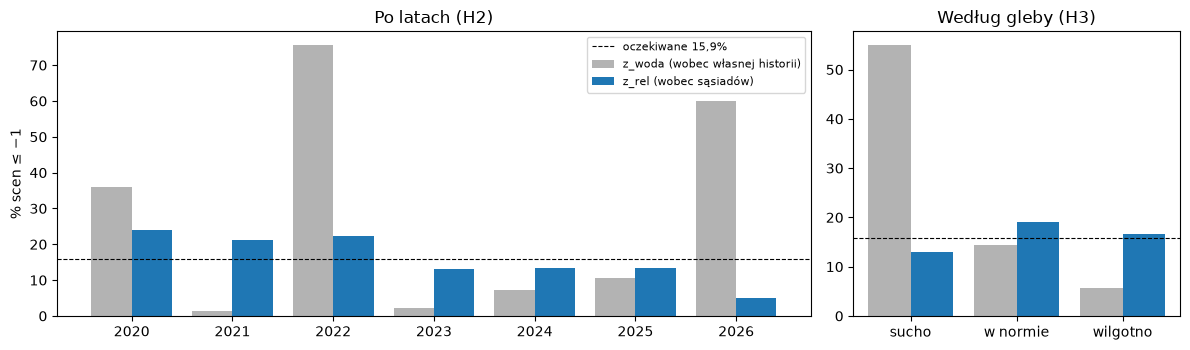

,z,z_rel,sceny
year,,,
2020,35.9,24.0,262
2021,1.3,21.1,237
2022,75.7,22.3,341
2023,2.3,13.0,262
2024,7.2,13.5,208
2025,10.5,13.4,306
2026,60.0,4.9,325


,z,z_rel,sceny
soil,,,
dry,55.0,13.0,878
normal,14.4,19.2,689
wet,5.6,16.6,374


H2: rozstęp z_rel 19.1 pp (z_woda 74.4 pp) → SPEŁNIONE
H3: |sucho − wilgotno| z_rel 3.6 pp (z_woda 49.4 pp) → SPEŁNIONE


In [4]:
by_year = pd.DataFrame({c: T.groupby('year').apply(share(c), include_groups=False) for c in ('z_rel', 'z')})
by_year['sceny'] = T.groupby('year').size()
by_soil = pd.DataFrame({c: T[T['soil'] != ''].groupby('soil').apply(share(c), include_groups=False) for c in ('z_rel', 'z')})
by_soil['sceny'] = T[T['soil'] != ''].groupby('soil').size()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={'width_ratios': [3, 1.3]})
x = np.arange(len(by_year))
ax[0].bar(x - 0.2, 100 * by_year['z'], 0.4, color='0.7', label='z_woda (wobec własnej historii)')
ax[0].bar(x + 0.2, 100 * by_year['z_rel'], 0.4, color='tab:blue', label='z_rel (wobec sąsiadów)')
ax[0].axhline(100 * P_BELOW, color='k', lw=0.8, ls='--', label='oczekiwane 15,9%')
ax[0].set_xticks(x, by_year.index); ax[0].set_ylabel('% scen ≤ −1'); ax[0].set_title('Po latach (H2)')
ax[0].legend(fontsize=8)
xs = np.arange(len(by_soil))
ax[1].bar(xs - 0.2, 100 * by_soil['z'], 0.4, color='0.7'); ax[1].bar(xs + 0.2, 100 * by_soil['z_rel'], 0.4, color='tab:blue')
ax[1].axhline(100 * P_BELOW, color='k', lw=0.8, ls='--')
ax[1].set_xticks(xs, ['sucho', 'w normie', 'wilgotno'][:len(by_soil)]); ax[1].set_title('Według gleby (H3)')
plt.tight_layout(); plt.show()

display((by_year[['z', 'z_rel']] * 100).round(1).join(by_year['sceny']))
display((by_soil[['z', 'z_rel']] * 100).round(1).join(by_soil['sceny']))
rng = {c: float(by_year[c].max() - by_year[c].min()) for c in ('z_rel', 'z')}
gap = {c: float(abs(by_soil.loc['dry', c] - by_soil.loc['wet', c])) for c in ('z_rel', 'z')}
H2, H3 = rng['z_rel'] <= 0.25, gap['z_rel'] <= 0.10
print(f"H2: rozstęp z_rel {100*rng['z_rel']:.1f} pp (z_woda {100*rng['z']:.1f} pp) → {'SPEŁNIONE' if H2 else 'NIESPEŁNIONE'}")
print(f"H3: |sucho − wilgotno| z_rel {100*gap['z_rel']:.1f} pp (z_woda {100*gap['z']:.1f} pp) → {'SPEŁNIONE' if H3 else 'NIESPEŁNIONE'}")

## 6. H4 — czy przesadzenia (RPG) wyróżniają się w z_rel
Sezon = winnica × rok (≥ 6 scen VI–IX). Miara: mediana |z_rel|. Zdarzenia: kody `VRN` / `RVI`, lata ≥ 2018.
Kryterium: średnia ranga zdarzeń ≥ 0,75 **i** p permutacyjne ≤ 0,05. Uwaga z protokołu: trzy z pięciu zdarzeń
mają już flagę W3b z tej samej różnicy d — to sprawdzenie spójności, nie niezależny dowód.

In [5]:
seas = T.groupby(['site_id', 'year']).agg(n=('z_rel', 'size'), m=('z_rel', lambda x: float(np.median(np.abs(x)))),
                                         med_zrel=('z_rel', 'median'), med_z=('z', 'median')).reset_index()
seas = seas[seas['n'] >= 6].reset_index(drop=True)
seas['rank'] = seas['m'].rank(pct=True)
ev = rpg[rpg['code_cultu'].isin(['VRN', 'RVI']) & (rpg['year'] >= 2018)][['site_id', 'year', 'code_cultu']]
ev_in = ev.merge(seas, on=['site_id', 'year'], how='left')
missing = ev_in[ev_in['m'].isna()]
ev_in = ev_in.dropna(subset=['m'])
display(ev_in[['site_id', 'year', 'code_cultu', 'n', 'med_z', 'med_zrel', 'm', 'rank']].round(2))
if len(missing):
    print('Zdarzenia bez miary (pominięte):', ', '.join(f'{a} {b}' for a, b in zip(missing.site_id, missing.year)))
k, stat = len(ev_in), float(ev_in['rank'].mean()) if len(ev_in) else np.nan
rng_ = np.random.default_rng(92)
perm = np.array([seas['rank'].to_numpy()[rng_.choice(len(seas), k, replace=False)].mean() for _ in range(10_000)])
p = float((perm >= stat).mean()) if k else np.nan
H4 = bool(k and stat >= 0.75 and p <= 0.05)
print(f'H4: {k} zdarzeń, średnia ranga {stat:.2f}, p = {p:.4f} ({len(seas)} sezonów) → {"SPEŁNIONE" if H4 else "NIESPEŁNIONE"}')

,site_id,year,code_cultu,n,med_z,med_zrel,m,rank
1,VINEYARD_13,2020,VRN,20.0,0.38,0.61,0.68,0.68
4,VINEYARD_22,2022,VRN,26.0,-0.06,1.55,1.55,0.95


Zdarzenia bez miary (pominięte): VINEYARD_13 2019, VINEYARD_22 2018, VINEYARD_22 2019


H4: 2 zdarzeń, średnia ranga 0.81, p = 0.0704 (91 sezonów) → NIESPEŁNIONE


## 7. Decyzja (reguła z protokołu §7)

In [6]:
res = pd.DataFrame([
    ('H1 kalibracja', f'{100*h1["z_rel"][0]:.1f}% [{100*h1["z_rel"][1]:.1f}; {100*h1["z_rel"][2]:.1f}]', f'{100*h1["z"][0]:.1f}%', H1),
    ('H2 rozstęp lat', f'{100*rng["z_rel"]:.1f} pp', f'{100*rng["z"]:.1f} pp', H2),
    ('H3 sucho − wilgotno', f'{100*gap["z_rel"]:.1f} pp', f'{100*gap["z"]:.1f} pp', H3),
    ('H4 przesadzenia', f'ranga {stat:.2f}, p = {p:.3f}', '—', H4)],
    columns=['test', 'z_rel', 'z_woda (te same sceny)', 'spełnione'])
display(res)
if H1 and H2 and H3 and H4:
    decision = 'KANDYDAT: z_rel spełnia H1–H4; pokazujemy dopiero po potwierdzeniu na sezonie 2027.'
elif H1 and H2 and H3:
    decision = 'NIE DODAJEMY: wielkość skalibrowana, ale sygnał winnicy (H4) niepokazany.'
else:
    decision = 'NIE PRZYJMUJEMY: niespełnione ' + ', '.join(n for n, ok in (('H1', H1), ('H2', H2), ('H3', H3)) if not ok) + '.'
print(decision)

,test,z_rel,z_woda (te same sceny),spełnione
0,H1 kalibracja,15.9% [8.9; 22.8],31.1%,True
1,H2 rozstęp lat,19.1 pp,74.4 pp,True
2,H3 sucho − wilgotno,3.6 pp,49.4 pp,True
3,H4 przesadzenia,"ranga 0.81, p = 0.070",—,False


NIE DODAJEMY: wielkość skalibrowana, ale sygnał winnicy (H4) niepokazany.


## 8. Opisowo (bez wpływu na decyzję)
Udziały z_rel ≥ +1 i |z_rel| ≥ 2, związek d z medianą sąsiadów i przebieg VINEYARD_06 (winnica przy stacji).

,≥ +1,|·| ≥ 2
z_rel,12.9,7.0
z,16.3,11.2


r(d, mediana sąsiadów) = -0.14; r(z_woda, mediana sąsiadów) = 0.80


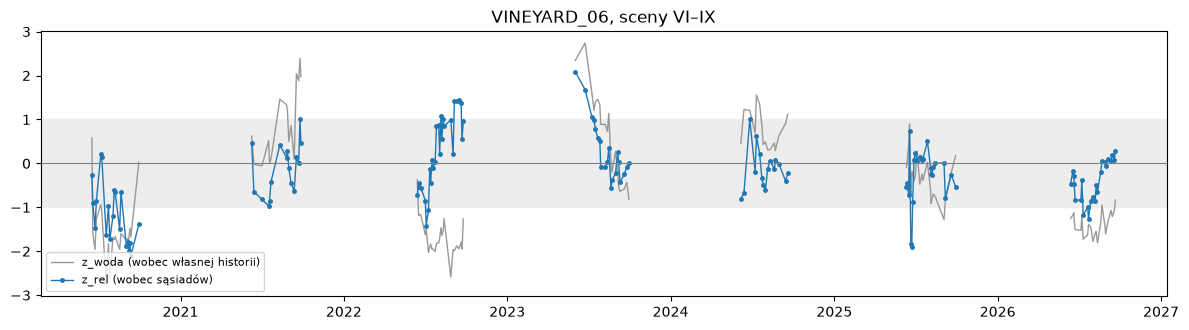

In [7]:
desc = pd.DataFrame({c: {'≥ +1': jk(T, share(c, 1, 'ge'))[0],
                         '|·| ≥ 2': float((T[c].abs() >= 2).mean())} for c in ('z_rel', 'z')}).T
display((desc * 100).round(1))
print(f"r(d, mediana sąsiadów) = {np.corrcoef(T['d'], T['nbr_med'])[0, 1]:.2f}; "
      f"r(z_woda, mediana sąsiadów) = {np.corrcoef(T['z'], T['nbr_med'])[0, 1]:.2f}")

site = cfg['MAIN_SITE']
g = D[(D.site_id == site) & D['summer'] & D['z_rel'].notna()].sort_values('day')
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.axhspan(-1, 1, color='0.93', zorder=0)
for i, (_, gy) in enumerate(g.groupby('year')):
    ax.plot(gy.day, gy.z, '-', color='0.6', lw=1, label='z_woda (wobec własnej historii)' if i == 0 else None)
    ax.plot(gy.day, gy.z_rel, '-o', ms=2.5, lw=1, color='tab:blue', label='z_rel (wobec sąsiadów)' if i == 0 else None)
ax.axhline(0, color='0.5', lw=0.8); ax.set_title(f'{site}, sceny VI–IX'); ax.legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.show()

## 9. Wnioski (przebieg 2026-10-25; pełny opis: `docs/evidence/W3e_wyniki.md`)
- **H1–H3 spełnione z dużym zapasem.** Porównanie z sąsiadami usuwa wspólną pogodę: udział „poniżej” 15,9%
  (oczekiwane 15,9%), po latach 5–24% zamiast 1–76%, sucho i wilgotno prawie tak samo (różnica 4 pp zamiast 49 pp).
- **H4 niespełnione** (p = 0,07): mierzalne były tylko 2 z 5 przesadzeń — trzy wcześniejsze przypadają na lata,
  w których z_rel jeszcze nie istnieje. To wada planu testu, widoczna przed liczeniem.
- **Decyzja (§7): nie dodajemy do karty.** Wielkość jest skalibrowana, ale nie pokazaliśmy, że wskazuje zdarzenia
  w samej winnicy. Dalej: powtórka H1–H3 na sezonie 2027 i nowy test sygnału na zdarzeniach, które da się zmierzyć.